Day 1 – Foundations of ML & Math Essentials
Objective: Understand the data, perform an 80:20 split using NumPy, and calculate statistical measures.

Import libraries and upload dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

print(df.head())
print(df.shape)
print(df.columns.tolist())

Saving crop_yield.csv to crop_yield (1).csv
           Crop  Crop_Year       Season  State     Area  Production  \
0      Arecanut       1997  Whole Year   Assam  73814.0       56708   
1     Arhar/Tur       1997  Kharif       Assam   6637.0        4685   
2   Castor seed       1997  Kharif       Assam    796.0          22   
3      Coconut        1997  Whole Year   Assam  19656.0   126905000   
4  Cotton(lint)       1997  Kharif       Assam   1739.0         794   

   Annual_Rainfall  Fertilizer  Pesticide        Yield  
0           2051.4  7024878.38   22882.34     0.796087  
1           2051.4   631643.29    2057.47     0.710435  
2           2051.4    75755.32     246.76     0.238333  
3           2051.4  1870661.52    6093.36  5238.051739  
4           2051.4   165500.63     539.09     0.420909  
(19689, 10)
['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']


Select Features

In [3]:
X = df["Annual_Rainfall"].to_numpy(dtype=float)
y = df["Yield"].to_numpy(dtype=float)

# Remove invalid values
valid = np.isfinite(X) & np.isfinite(y)

X = X[valid]
y = y[valid]

print("Samples:", len(X))

Samples: 19689


Perform 80:20 split using pure NumPy

In [4]:
np.random.seed(42)

indices = np.random.permutation(len(X))

split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 15751
Testing samples: 3938


Calculate mean, variance and standard deviation

In [5]:
print("RAINFALL STATISTICS")

print("Mean:", np.mean(X_train))
print("Variance:", np.var(X_train))
print("Standard Deviation:", np.std(X_train))

print("\nCROP YIELD STATISTICS")

print("Mean:", np.mean(y_train))
print("Variance:", np.var(y_train))
print("Standard Deviation:", np.std(y_train))

RAINFALL STATISTICS
Mean: 1438.2842864000445
Variance: 667725.9277936673
Standard Deviation: 817.1449857850608

CROP YIELD STATISTICS
Mean: 78.24302736864765
Variance: 765302.2210159508
Standard Deviation: 874.8155354221544


Visualize the dataset

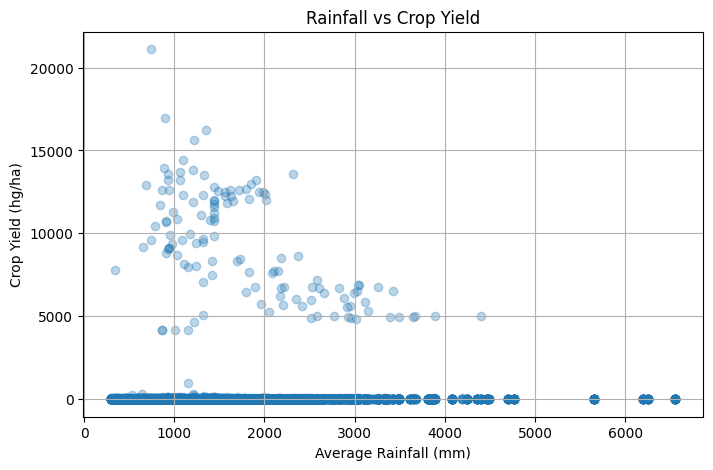

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(X_train, y_train, alpha=0.3)

plt.xlabel("Average Rainfall (mm)")
plt.ylabel("Crop Yield (hg/ha)")
plt.title("Rainfall vs Crop Yield")

plt.grid()
plt.show()